# Vision — Citra Satelit Multispektral: Klasifikasi Tutupan Lahan
**Kapan dipakai:** tema pangan / ekonomi hijau: sawah vs tanah kosong, deforestasi,
kekeringan, pemetaan kebun. Citra satelit punya **band** di luar RGB (inframerah dekat/NIR).
Tanaman sehat memantulkan NIR kuat dan menyerap merah, maka indeks seperti NDVI informatif.

**Langkah:** fitur per band (rata-rata, tengah, sebaran) + indeks vegetasi/air → model tabular.

**Data demo:** Statlog Landsat (satimage). Satu baris = jendela 3×3 piksel × 4 band = 36 kolom,
urut piksel kiri-atas → kanan-bawah, tiap piksel 4 band (hijau, merah, NIR1, NIR2). Target =
tutupan lahan piksel tengah. Data demo sudah distandarkan (rata-rata 0), jadi indeks ditulis
sebagai **selisih** band. Data asli 0–255: NDVI = (NIR − merah)/(NIR + merah).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/satelit"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/satimage_train.csv"
TEST_CSV = f"{DATA_FOLDER}/satimage_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/satimage_test_labels.csv"   # hanya ada di data latihan

TARGET = "kelas"
BANDS = ["hijau", "merah", "nir1", "nir2"]
N_PIXELS = 9          # jendela 3×3
CENTER_PIXEL = 4      # piksel ke-5 (mulai 0) = tengah
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
PIXEL_COLS = list(test.columns.drop("id"))   # 36 kolom: piksel 1 band 1..4, piksel 2, dst
print("train:", train.shape, "| test:", test.shape)
missing = train.isna().sum()
print("missing:", missing.sum())
train.head()

train: (4822, 38) | test: (1608, 37)
missing: 0


,id,Aattr,Battr,Cattr,Dattr,Eattr,Fattr,A1attr,B2attr,C3attr,...,D22attr,E23attr,F24attr,A25attr,B26attr,C27attr,D28attr,E29attr,F30attr,kelas
0,3621,0.632080,0.148811,-0.437980,-0.878029,0.357618,-0.010640,-0.426705,-0.870978,0.080742,...,-0.719309,0.374717,0.037396,-0.605346,-0.715095,0.393417,0.225319,-0.354948,-0.341412,tanah_abu_lembap
1,5611,0.117596,0.848043,0.583289,0.233219,0.136399,1.212789,0.833490,0.712894,0.154978,...,-0.192752,-0.144082,0.693931,0.651815,0.177591,0.169563,1.277169,1.202359,0.813184,tanah_merah
2,3437,1.661048,0.848043,0.823588,0.286136,1.389975,1.038013,0.533444,0.501711,1.713929,...,0.491773,1.560545,1.306698,0.771544,0.492656,1.587304,1.320996,0.783084,0.340849,tanah_abu
3,4857,1.514052,0.891745,1.063887,0.339052,1.906154,1.125401,0.773481,0.343324,1.936636,...,0.228494,1.782888,1.219160,0.651815,0.230101,1.811158,1.233342,0.902877,0.393331,tanah_abu
4,1306,1.367057,1.809488,2.205306,1.185718,1.389975,1.824503,1.553602,1.029669,1.120043,...,0.491773,1.412317,0.869008,0.591950,0.230101,1.139596,1.058033,0.842981,0.235886,tanah_abu


## Fitur band: rata-rata 9 piksel, piksel tengah, sebaran (tekstur), indeks vegetasi

In [4]:
def add_features(table):
    table = table.copy()
    for band_number in range(len(BANDS)):
        name = BANDS[band_number]
        band_cols = []
        for pixel in range(N_PIXELS):
            band_cols.append(PIXEL_COLS[len(BANDS) * pixel + band_number])
        table[name + "_rata"] = table[band_cols].mean(axis=1)
        table[name + "_tengah"] = table[band_cols[CENTER_PIXEL]]
        table[name + "_std"] = table[band_cols].std(axis=1)
    table["indeks_vegetasi"] = table["nir2_rata"] - table["merah_rata"]
    table["indeks_vegetasi_tengah"] = table["nir2_tengah"] - table["merah_tengah"]
    table["indeks_air"] = table["hijau_rata"] - table["nir2_rata"]
    table["kecerahan"] = table[["hijau_rata", "merah_rata", "nir1_rata", "nir2_rata"]].mean(axis=1)
    return table


train = add_features(train)
test = add_features(test)
NEW_FEATURES = list(train.columns.drop(["id", TARGET] + PIXEL_COLS))
FEATURES = PIXEL_COLS + NEW_FEATURES
print(NEW_FEATURES)

['hijau_rata', 'hijau_tengah', 'hijau_std', 'merah_rata', 'merah_tengah', 'merah_std', 'nir1_rata', 'nir1_tengah', 'nir1_std', 'nir2_rata', 'nir2_tengah', 'nir2_std', 'indeks_vegetasi', 'indeks_vegetasi_tengah', 'indeks_air', 'kecerahan']


## EDA: tiap kelas punya "sidik spektral" berbeda

kelas
tanah_merah                1148
tanah_abu_sangat_lembap    1131
tanah_abu                  1017
tanah_vegetasi              530
kapas                       527
tanah_abu_lembap            469
Name: count, dtype: int64


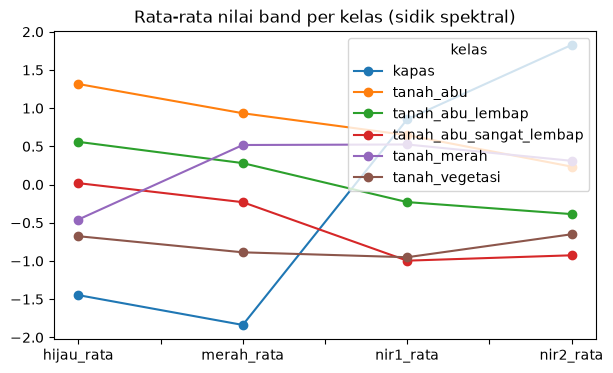

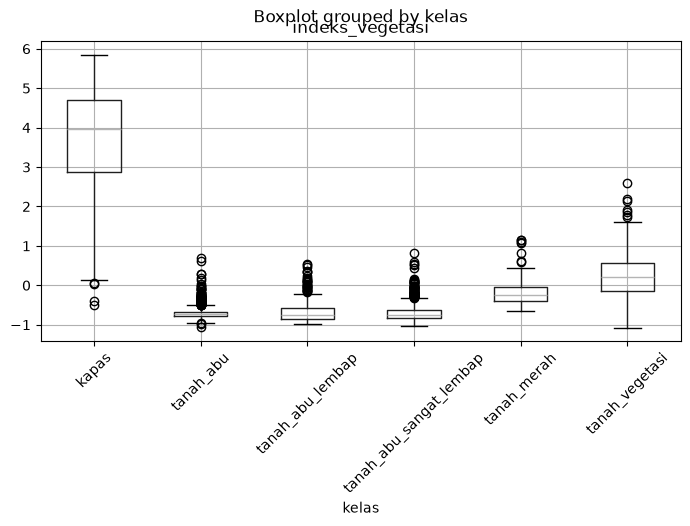

In [5]:
print(train[TARGET].value_counts())
profile = train.groupby(TARGET)[["hijau_rata", "merah_rata", "nir1_rata", "nir2_rata"]].mean()
profile.T.plot(marker="o", figsize=(7, 4))
plt.title("Rata-rata nilai band per kelas (sidik spektral)")
plt.show()
train.boxplot(column="indeks_vegetasi", by=TARGET, rot=45, figsize=(8, 4))
plt.show()

## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train[FEATURES], train[TARGET], test_size=0.25, stratify=train[TARGET], random_state=SEED
)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
model = LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

model.fit(X_train, y_train)

,learning_rate,0.05
,n_estimators,500
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


## Evaluasi di validasi

F1 macro: 0.9119
                         precision    recall  f1-score   support

                  kapas       0.96      0.98      0.97       132
              tanah_abu       0.89      0.96      0.93       254
       tanah_abu_lembap       0.82      0.72      0.76       117
tanah_abu_sangat_lembap       0.92      0.93      0.93       283
            tanah_merah       0.98      0.98      0.98       287
         tanah_vegetasi       0.94      0.87      0.90       133

               accuracy                           0.93      1206
              macro avg       0.92      0.91      0.91      1206
           weighted avg       0.93      0.93      0.93      1206



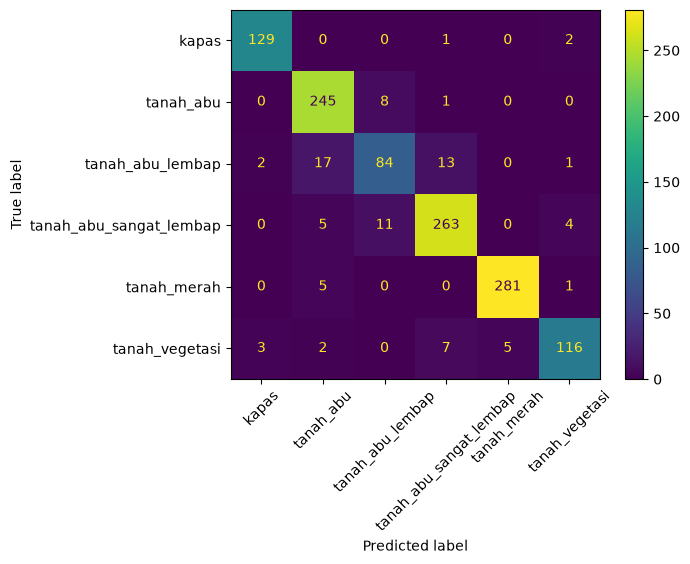

In [8]:
val_predictions = model.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=45)
plt.show()

## Apakah fitur indeks membantu? (CV 5-fold di data latih)

In [9]:
raw_scores = cross_val_score(model, train[PIXEL_COLS], train[TARGET], cv=5, scoring="f1_macro")
all_scores = cross_val_score(model, train[FEATURES], train[TARGET], cv=5, scoring="f1_macro")
print("36 piksel mentah F1 macro CV:", round(raw_scores.mean(), 4))
print("piksel + indeks  F1 macro CV:", round(all_scores.mean(), 4))

36 piksel mentah F1 macro CV: 0.9006
piksel + indeks  F1 macro CV: 0.9155


## Latih ulang di semua data + submission

In [10]:
model.fit(train[FEATURES], train[TARGET])
predictions = model.predict(test[FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["kelas"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,kelas
0,4298,kapas
1,5987,tanah_abu_lembap
2,1404,tanah_abu_sangat_lembap
3,2883,tanah_abu_sangat_lembap
4,2610,tanah_vegetasi


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [11]:
test_key = pd.read_csv(TEST_KEY_CSV)["kelas"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.9022
